# Figura 3: diagrama de bifurcação e maior expoente de Lyapunov

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SEU-USUARIO/pendulo-caotico/blob/main/03_diagrama_de_bifurcacao.ipynb)

Notebook de apoio ao artigo *Caracterização do caos no pêndulo forçado e amortecido: instabilidade, informação e geometria do espaço de fase*, **Seção III, Figura 3**.

A amplitude do forçamento $f$ é varrida de 0,9 a 1,5. Para cada valor registram-se (a) os valores estroboscópicos de $\omega$, que formam o diagrama de bifurcação, e (b) o maior expoente de Lyapunov $\lambda_{\max}$. A figura reúne em uma só imagem todos os regimes do sistema no domínio estudado no artigo.

**Tempo de execução:** cerca de 10 segundos.

## Como ler o diagrama

Para cada $f$, depois de descartar o transiente, marcam-se os valores $\omega_n = \omega(t_0 + nT_d)$ de 50 períodos consecutivos (Eq. 4). Se a órbita tem período $mT_d$, a coluna tem $m$ pontos distintos; se é caótica, a coluna se preenche. A sequência $1 \to 2 \to 4 \to \dots$ de pontos antes das bandas densas é a rota por duplicação de período.

O painel (b) confirma a leitura: $\lambda_{\max} < 0$ nas colunas com poucos pontos e $\lambda_{\max} > 0$ nas colunas preenchidas. Em cada bifurcação, $\lambda_{\max}$ sobe até tocar zero, porque um multiplicador de Floquet atravessa o círculo unitário.

O sistema, a equação variacional e o integrador são os mesmos do Notebook 02 (Eqs. 3 e 6; no código, $q$ se chama `beta`).

## Código

### 1. Bibliotecas, parâmetros e integrador

`deriv` e `rk4_full` integram o estado $(\theta, \omega)$ e o vetor tangente $(\delta\theta, \delta\omega)$ com RK4 de passo fixo. O `@njit` do Numba compila as funções.

In [1]:
# Dependências: numpy, matplotlib e numba.
# No Colab o Numba normalmente já vem instalado; se faltar, descomente a linha abaixo.
# !pip install numba

import numpy as np
import math
import matplotlib.pyplot as plt
from pathlib import Path
from numba import njit  # compila as funções numéricas

FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)

# ---- parâmetros do pêndulo ----
beta  = 0.5
Omega = 2/3
T_D   = 2*math.pi/Omega

@njit
def deriv(tt, x, y, a, b, f):
    fx = y
    fy = -beta*y - math.sin(x) + f*math.cos(Omega*tt)
    fa = b
    fb = -math.cos(x)*a - beta*b
    return fx, fy, fa, fb

@njit
def rk4_full(t, th, w, dth, dw, dt, f):
    fx1, fy1, fa1, fb1 = deriv(t, th, w, dth, dw, f)

    t2 = t + dt/2
    fx2, fy2, fa2, fb2 = deriv(t2, th + dt*fx1/2, w + dt*fy1/2, dth + dt*fa1/2, dw + dt*fb1/2, f)

    fx3, fy3, fa3, fb3 = deriv(t2, th + dt*fx2/2, w + dt*fy2/2, dth + dt*fa2/2, dw + dt*fb2/2, f)

    t3 = t + dt
    fx4, fy4, fa4, fb4 = deriv(t3, th + dt*fx3, w + dt*fy3, dth + dt*fa3, dw + dt*fb3, f)

    th  = th  + (dt/6)*(fx1 + 2*fx2 + 2*fx3 + fx4)
    w   = w   + (dt/6)*(fy1 + 2*fy2 + 2*fy3 + fy4)
    dth = dth + (dt/6)*(fa1 + 2*fa2 + 2*fa3 + fa4)
    dw  = dw  + (dt/6)*(fb1 + 2*fb2 + 2*fb3 + fb4)

    return th, w, dth, dw

### 2. Varredura em $f$

A função `calcular` percorre os valores de $f$ e, para cada um, faz duas etapas.

1. **Bifurcação.** Integra `n_trans` = 300 períodos de transiente e registra $\omega$ nos `n_rec` = 50 períodos seguintes.
2. **Lyapunov.** A partir do último estado, integra `n_lyap` = 400 períodos com o vetor tangente iniciado em $(1, 0)$, acumulando $\ln r$ e renormalizando a cada período. É uma estimativa curta: basta para o sinal de $\lambda_{\max}$, mas tem flutuações visíveis na terceira casa decimal.

Três detalhes de implementação:

- **Continuação.** O estado final de um valor de $f$ é a condição inicial do seguinte (`th, w` não são reiniciados). O sistema acompanha continuamente o mesmo ramo de atrator, e o transiente de cada $f$ só precisa acomodar uma mudança pequena. Onde há atratores coexistentes, o resultado pode depender do sentido da varredura.
- **Fase do forçamento.** O tempo recomeça em $t = 0$ a cada $f$. Como o estado anterior foi registrado em um múltiplo inteiro de $T_d$, a fase do forçamento continua coerente.
- **Pré-alocação.** Os vetores de saída são criados com `np.empty` em vez de crescerem com `append`, o que permite ao Numba compilar a função inteira.

In [2]:
@njit
def calcular(f_arr, spp, n_trans, n_rec, n_lyap, dt):
    th, w = 0.2, 0.0

    # Pré-alocação dos arrays de saída
    n_pontos = len(f_arr) * n_rec
    allF = np.empty(n_pontos)
    allW = np.empty(n_pontos)
    lam_list = np.empty(len(f_arr))

    idx = 0
    for i in range(len(f_arr)):
        f = f_arr[i]

        # --- bifurcação: transiente + registro estroboscópico de ω ---
        t = 0.0
        for n in range(n_trans + n_rec):
            for _ in range(spp):
                th, w, _, _ = rk4_full(t, th, w, 0.0, 0.0, dt, f)
                t += dt
            if n >= n_trans:
                allF[idx] = f
                allW[idx] = w
                idx += 1

        # --- Lyapunov: dinâmica tangente com renormalização por período ---
        thl, wl, dth, dw, logsum, t2 = th, w, 1.0, 0.0, 0.0, 0.0
        for n in range(n_lyap):
            for _ in range(spp):
                thl, wl, dth, dw = rk4_full(t2, thl, wl, dth, dw, dt, f)
                t2 += dt

            r = math.hypot(dth, dw)
            logsum += math.log(r)
            dth = dth / r
            dw = dw / r

        lam_list[i] = logsum / (n_lyap * T_D)

    return allF, allW, lam_list

### 3. Execução

400 valores de $f$ igualmente espaçados em $[0{,}9;\ 1{,}5]$, com 80 passos por período ($\Delta t = T_d/80$).

In [3]:
f_arr = np.linspace(0.9, 1.5, 400)
spp, n_trans, n_rec, n_lyap = 80, 300, 50, 400
dt = T_D/spp

allF, allW, lam = calcular(f_arr, spp, n_trans, n_rec, n_lyap, dt)

### 4. Figura

As linhas verticais tracejadas marcam $f = 1{,}07$ e $f = 1{,}35$.

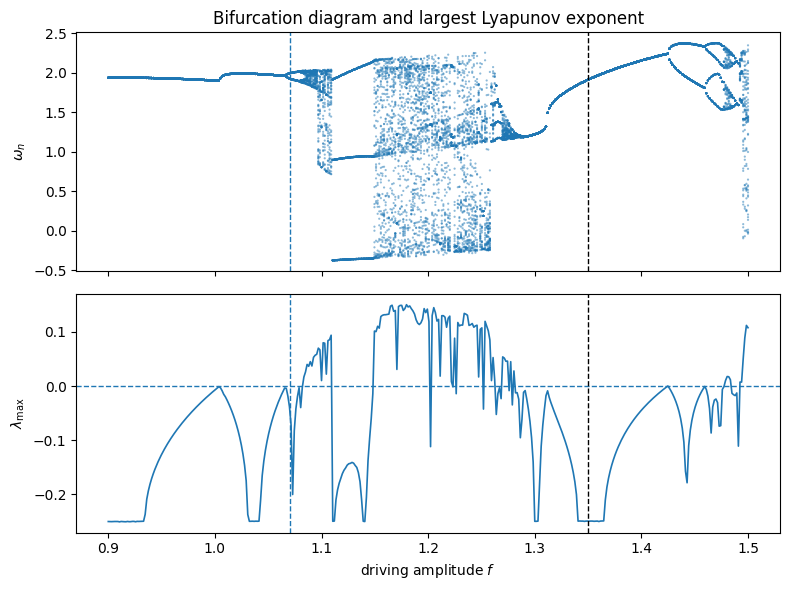

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

ax1.scatter(allF, allW, s=2.5, color='C0', alpha=0.5, edgecolors='none')
ax1.axvline(1.07, color='C0', ls='--', lw=1)
ax1.axvline(1.35, color='black', ls='--', lw=1)
ax1.set_ylabel(r'$\omega_n$')
ax1.set_title('Bifurcation diagram and largest Lyapunov exponent')

ax2.plot(f_arr, lam, color='C0', lw=1.2)
ax2.axhline(0, color='C0', ls='--', lw=1)
ax2.axvline(1.07, color='C0', ls='--', lw=1)
ax2.axvline(1.35, color='black', ls='--', lw=1)
ax2.set_xlabel(r'driving amplitude $f$')
ax2.set_ylabel(r'$\lambda_{\max}$')

fig.tight_layout()
fig.savefig(FIG_DIR / 'figura3_bifurcacao_lyapunov.png', dpi=300, bbox_inches='tight')
plt.show()

### 5. Os dois regimes do artigo na varredura

A célula abaixo lê, na própria varredura, $\lambda_{\max}$ e o número de valores distintos de $\omega_n$ nos pontos mais próximos de $f = 0{,}9$ e $f = 1{,}2$, e mede a fração do domínio com $\lambda_{\max} > 0$.

In [5]:
for f0 in (0.9, 1.2):
    i = int(np.argmin(abs(f_arr - f0)))
    wn = allW[allF == f_arr[i]]
    n_dist = len(np.unique(np.round(wn, 4)))
    print(f"f = {f_arr[i]:.4f}:  λ_max = {lam[i]:+.4f}   valores distintos de ω_n (em 50) = {n_dist}")

caos = lam > 0
print(f"\nfração dos valores de f com λ_max > 0: {caos.mean():.2f}")
print(f"primeiro f com λ_max > 0: {f_arr[caos][0]:.4f}")

f = 0.9000:  λ_max = -0.2500   valores distintos de ω_n (em 50) = 1
f = 1.1992:  λ_max = +0.1420   valores distintos de ω_n (em 50) = 50

fração dos valores de f com λ_max > 0: 0.27
primeiro f com λ_max > 0: 1.0835


## Leitura dos resultados

A varredura reproduz a Figura 3 do artigo. Em $f = 0{,}9$ a coluna tem um único valor de $\omega_n$ e $\lambda_{\max} = -0{,}250$, o mesmo resultado do Notebook 02. Em $f \approx 1{,}2$ os 50 valores de $\omega_n$ são todos distintos e $\lambda_{\max} \approx 0{,}14$. A diferença em relação aos valores 0,128 a 0,133 dos Notebooks 02 e 05 vem da estimativa curta, de 400 períodos. Cerca de 27% dos valores de $f$ no domínio têm $\lambda_{\max} > 0$.

Percorrendo o diagrama da esquerda para a direita:

- até $f \approx 1{,}07$ a órbita tem período $T_d$, com uma pequena descontinuidade em $f \approx 1{,}00$, onde $\lambda_{\max}$ toca zero;
- perto de $f = 1{,}07$ (linha azul) ocorre a primeira duplicação de período, e a cascata leva ao caos em $f \approx 1{,}08$;
- entre $f \approx 1{,}11$ e $1{,}15$ há uma janela de período 3 (três ramos, $\lambda_{\max} < 0$);
- de $f \approx 1{,}15$ a $1{,}26$ fica a banda caótica principal, que contém o regime $f = 1{,}2$ do artigo, entremeada de janelas periódicas estreitas;
- entre $1{,}26$ e $1{,}31$ o caos se fragmenta e as órbitas se simplificam até voltar ao período $T_d$;
- de $f \approx 1{,}31$ a $1{,}42$ a órbita tem período $T_d$; a linha preta ($f = 1{,}35$) está nessa janela;
- a partir de $f \approx 1{,}42$ uma nova cascata de duplicações leva de novo ao caos perto de $f = 1{,}5$.

Nos trechos em que $\lambda_{\max}$ fica exatamente em $-0{,}25 = -q/2$, os multiplicadores de Floquet da órbita são complexos conjugados, como explicado no Notebook 02. Nos trechos em que ele sobe até zero, os multiplicadores são reais e um deles se aproxima do círculo unitário, o que anuncia uma bifurcação.

## Para explorar

- Inverta a varredura (`f_arr = np.linspace(1.5, 0.9, 400)`) e procure trechos em que o diagrama muda: indicam atratores coexistentes (histerese).
- Aumente `n_lyap` para 2000 e compare a suavidade da curva de $\lambda_{\max}$.
- Amplie uma janela periódica (por exemplo, `np.linspace(1.33, 1.37, 400)`) para ver sua própria cascata de duplicações.